# Example 1: Function Fitting

In this example, we will cover how to leverage grid refinement to maximimze KANs' ability to fit functions

intialize model and create dataset

In [1]:
import torch
from xkan import KANNetwork, create_dataset, fit
from xkan.interp import refine

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

# initialize KAN with G=3
model = KANNetwork([2, 1, 1], grid=3, k=3, seed=1, device=device)

# create dataset: training and test sets, inputs under 'x', labels under 'y'
f = lambda x: torch.exp(torch.sin(torch.pi*x[:,[0]]) + x[:,[1]]**2)
train, test = create_dataset(f, n_var=2, device=device)

cuda


Train KAN (grid=3)

In [2]:
history = fit(model, train, test, steps=20)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

train RMSE 0.013749912650978278 test RMSE 0.014012901894752527


The loss plateaus. we want a more fine-grained KAN!

In [3]:
# initialize a more fine-grained KAN with G=10 (the curves refitted on the training inputs)
model = refine(model, 10, train['x'])

Train KAN (grid=10)

In [4]:
history = fit(model, train, test, steps=20)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

train RMSE 0.0007798283216548351 test RMSE 0.0007984908023352341


The loss becomes lower. This is good! Now we can even iteratively making grids finer.

In [5]:
import numpy as np
import torch
from xkan import KANNetwork, create_dataset, fit
from xkan.interp import refine

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

# create dataset
f = lambda x: torch.exp(torch.sin(torch.pi*x[:,[0]]) + x[:,[1]]**2)
train, test = create_dataset(f, n_var=2, device=device, train_num=1000)


grids = np.array([3,5,10,20,50,100])
#grids = np.array([3,10])


train_losses = []
test_losses = []
steps = 200
k = 3

for i in range(grids.shape[0]):
    if i == 0:
        model = KANNetwork([2, 1, 1], grid=grids[i], k=k, seed=0, device=device)
    if i != 0:
        model = refine(model, grids[i], train['x'])
    history = fit(model, train, test, steps=steps)
    # the history holds mean squared errors: RMSE per step
    train_losses += list(np.sqrt(history['train/y']))
    test_losses += list(np.sqrt(history['val/y']))
    print(f'grid {grids[i]}: train RMSE {train_losses[-1]:.3e}, test RMSE {test_losses[-1]:.3e}')

cuda


grid 3: train RMSE 1.353e-02, test RMSE 1.385e-02


grid 5: train RMSE 7.258e-03, test RMSE 7.193e-03


grid 10: train RMSE 4.743e-04, test RMSE 4.961e-04


grid 20: train RMSE 4.896e-05, test RMSE 7.331e-05


grid 50: train RMSE 1.941e-05, test RMSE 4.384e-05


grid 100: train RMSE 1.559e-05, test RMSE 4.610e-05


Training dynamics of losses display staircase structures (loss suddenly drops after grid refinement)

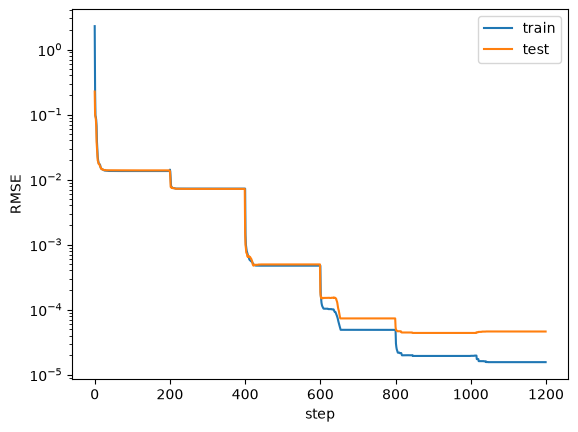

In [6]:
import matplotlib.pyplot as plt

plt.plot(train_losses)
plt.plot(test_losses)
plt.legend(['train', 'test'])
plt.ylabel('RMSE')
plt.xlabel('step')
plt.yscale('log')

Neural scaling laws (For some reason, this got worse than pykan 0.0. We're still investigating the reason, probably due to the updates of curve2coef)

Text(0, 0.5, 'RMSE')

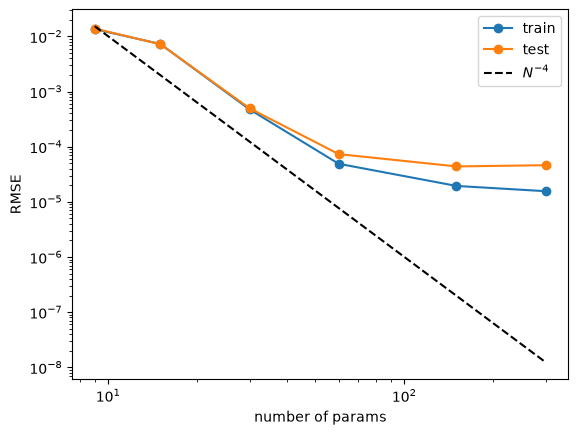

In [7]:
n_params = 3 * grids
train_vs_G = train_losses[(steps-1)::steps]
test_vs_G = test_losses[(steps-1)::steps]
plt.plot(n_params, train_vs_G, marker="o")
plt.plot(n_params, test_vs_G, marker="o")
plt.plot(n_params, 100*n_params**(-4.), ls="--", color="black")
plt.xscale('log')
plt.yscale('log')
plt.legend(['train', 'test', r'$N^{-4}$'])
plt.xlabel('number of params')
plt.ylabel('RMSE')